## TCAV: ImageNet

Load default ResNet50 trained on ImageNet and predict concepts for several classes.

In [1]:
!pwd
import sys
sys.path.append('./xplique/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import glob, cv2, pickle, os, time
from sklearn.metrics import label_ranking_average_precision_score as lrap
from scipy.stats import ttest_ind
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.metrics.pairwise import cosine_similarity
from tensorflow.keras.applications import ResNet50
from xplique.concepts import Cav, Tcav

2024-03-21 14:12:16.660051: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-03-21 14:12:17.102929: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1
Physical devices cannot be modified after being initialized


2024-03-21 14:12:17.727921: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
IMAGES_PATH   = '../data/Unsplash/images/'
CONCEPTS_PATH = '../data/Unsplash/concepts_broden/'
img_height = img_width = 224

### Load Test Images

In [5]:
classes = [c.split('/')[-1] for c in sorted(glob.glob(IMAGES_PATH + '*'))]
classes

['cheetah', 'snake', 'tiger', 'turtle', 'zebra']

In [6]:
test_set = tf.keras.utils.image_dataset_from_directory(
    IMAGES_PATH,
    shuffle=False,
    seed=123,
    image_size=(img_height, img_width),
    batch_size=None)

Found 212 files belonging to 5 classes.


In [7]:
# Keep a copy of unpreprocessed images
test_set_orig = test_set

In [8]:
# Preprocess raw images (required by resnet initialized with imagenet weights)
test_set = test_set.map(lambda x, y: (tf.keras.applications.resnet50.preprocess_input(x), y))

In [9]:
# Get concept label vector from tf.Dataset
y_true_img = np.asarray([lab.numpy() for _, lab in test_set])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


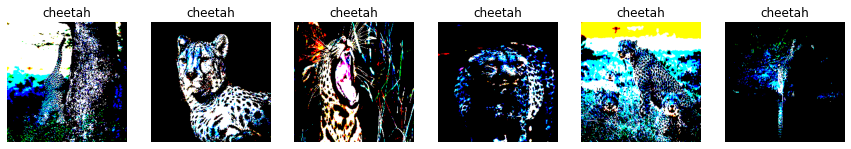

In [10]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = 6
with tf.device('/CPU:0'):
    i=0
    for img, lab in test_set.take(num_cols):
        plt.subplot(1, num_cols, i + 1)
        plt.imshow(img)
        plt.title(classes[lab.numpy()])
        plt.axis("off")
        i+=1
plt.show()

### Load random images from broden

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

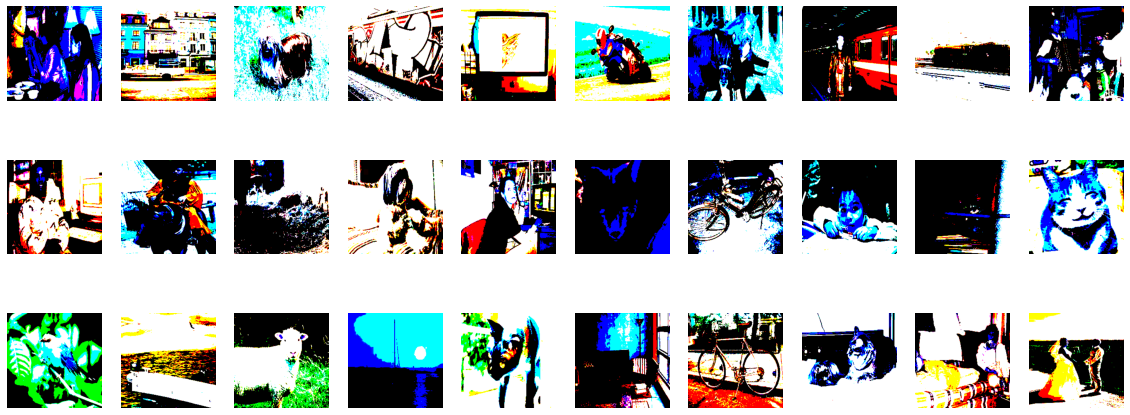

In [11]:
random_img_folder = '../data/broden1_224/images/pascal/'
input_size = img_height

random_imgs = os.listdir(random_img_folder)
random_imgs_filter = lambda f : all([rm not in f for rm in ['object', 'color', 'part']]) # only take 'natural' image

# Load same random images used for tcav fungi
with open('./beexplainable/metafiles/Fungi/raw/fungi_tcav_random.pickle', 'rb') as handle:
    files = pickle.load(handle)

random_dataset = [cv2.imread(random_img_folder+img)[...,::-1] for img in files]
random_dataset = [tf.image.resize(img, [img_width, img_height]) for img in random_dataset]
random_dataset = np.array([tf.keras.applications.resnet50.preprocess_input(img) for img in random_dataset])

plt.figure(figsize = (20, 8))
for i in range(30):
    plt.subplot(3, 10, i+1)
    plt.imshow(random_dataset[i])
    plt.axis('off')

### Load Concept Images

In [12]:
concepts_folder = CONCEPTS_PATH

concepts_files = os.listdir(concepts_folder)
concepts_availables = np.unique([t for t in concepts_files])
print('The available concepts are : \n', '; '.join(concepts_availables))

def load_concepts(concepts):
    files = glob.glob(CONCEPTS_PATH + concepts + '/*.jpg')
    imgs  = [cv2.imread(img)[...,::-1] for img in files]
    imgs  = [tf.image.resize(img, [img_width, img_height]) for img in imgs]
    imgs = [tf.keras.applications.resnet50.preprocess_input(img) for img in imgs]

    return np.array(imgs)

The available concepts are : 
 chequered; dotted; striped


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).




Texture: chequered  - shape: (30, 224, 224, 3)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


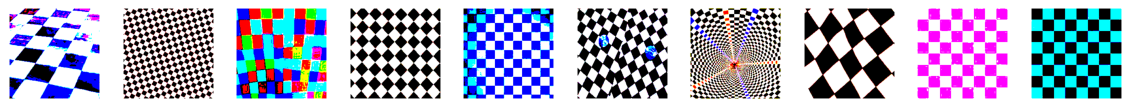

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i



Texture: dotted  - shape: (30, 224, 224, 3)


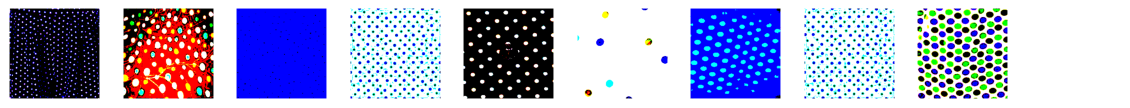

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i



Texture: striped  - shape: (30, 224, 224, 3)


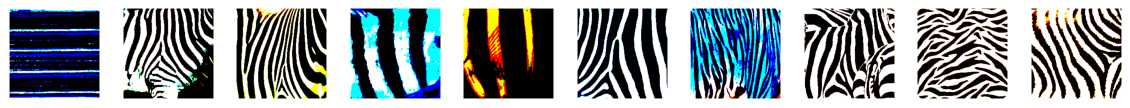

In [13]:
concepts = {concepts: load_concepts(concepts) for concepts in concepts_availables}

plt.rcParams["figure.figsize"] = [20, 8]
for concepts_name, images in concepts.items():
    print(f"\n\nTexture: {concepts_name}  - shape: {images.shape}")
    for i in range(10):
        plt.subplot(1, 10, i+1)
        plt.imshow(images[i])
        plt.axis('off')
    plt.show()

### Extract CAVs

In [14]:
# Load ResNet pretrained on ImageNet
model = ResNet50(input_shape=(img_height, img_width, 3), weights='imagenet', include_top=True)

In [15]:
# Define layer whose outputs will represent the latent space for the CAV
layer_target = 'avg_pool'

# Remove the softmax because we are only interested in the value of the logits
model.layers[-1].activation = tf.keras.activations.linear

In [16]:
cavs = {}
nb_repeat = 30
cav_extractor = Cav(model, layer_target, batch_size=64)
for concepts_name, imgs in concepts.items():

    for repeat_id in range(nb_repeat):
        # Choose different random images for each cav repetition
        random_ids = np.random.choice(len(random_dataset), len(imgs), replace = False)
        cav = cav_extractor(imgs, random_dataset[random_ids])

        if concepts_name not in cavs:
            cavs[concepts_name] = []

        cavs[concepts_name].append(cav)

    print(f"Done for concept {concepts_name}.")

2024-03-21 14:12:26.771756: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2024-03-21 14:12:27.260060: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-21 14:12:27.260800: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-21 14:12:27.260834: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-03-21 14:12:27.262092: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-21 14:12:27.262191: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


Done for concept chequered.
Done for concept dotted.
Done for concept striped.


In [17]:
# Do the same things for random images
for repeat_id in range(nb_repeat):
    # Choose many random images, half as positive and half as negative
    random_ids = np.random.choice(len(random_dataset), 500, replace = False)
    random_1, random_2 = random_ids[:250], random_ids[250:]

    cav = cav_extractor(random_dataset[random_1], random_dataset[random_2])

    if 'random' not in cavs:
        cavs['random'] = []

    cavs['random'].append(cav)

print(f"Done for Random.")

Done for Random.


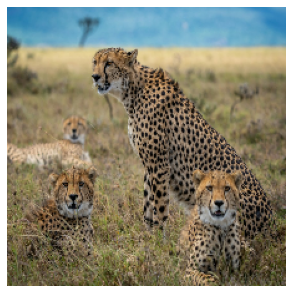

In [60]:
# Pick an example
ex_ind = 4
imgs_cav = test_set.skip(ex_ind).take(1)
img_orig = test_set_orig.skip(ex_ind).take(1)
imgs_cav = imgs_cav.map(lambda img_cav, lab: tf.numpy_function(np.array, [img_cav], tf.float32))
img_orig = img_orig.map(lambda img_orig, lab: tf.numpy_function(np.array, [img_orig], tf.float32))
imgs_cav = list(imgs_cav.as_numpy_iterator())
img_orig = list(img_orig.as_numpy_iterator())
imgs_cav = np.array(imgs_cav)
img_orig = np.array(img_orig)/255.
plt.figure(figsize=(5, 6))
plt.imshow(img_orig[0])
plt.axis('off');

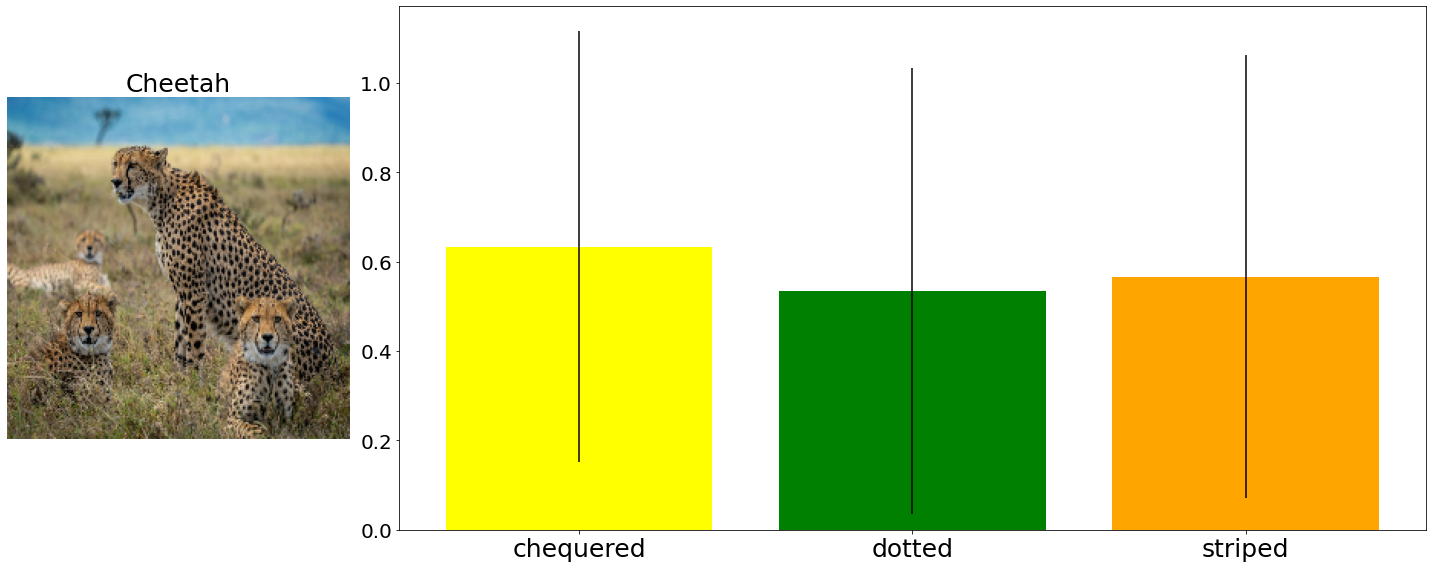

In [61]:
### Compute TCAV scores ###
cav_tester = Tcav(model, layer_target)
tcav_scores = {}

# For the chosen concept, we take all the CAVs and test them against that class
for concept_name, _cavs in cavs.items():
    tcav_scores[concept_name] = []
    for cav in _cavs:
        score = cav_tester(imgs_cav, y_true_img[ex_ind], cav)
        tcav_scores[concept_name].append(score)

concept_score = []
for concept_id, concept_name in enumerate(tcav_scores.keys()):
    scores = tcav_scores[concept_name]
    mean = np.mean(scores)
    std = np.std(scores)
    concept_score.append((concept_name, mean, std))

means = [mean for concept_name, mean, std in concept_score][:-1] # leave out random part
stds  = [std  for concept_name, mean, std in concept_score][:-1]

# Plot bars along with stds and explained image next to them
font_size = 25
f, (a0, a1) = plt.subplots(1, 2, gridspec_kw = {'width_ratios': [1, 3]})

a0.imshow(img_orig[0])
a0.axis('off')
a0.set_title(classes[y_true_img[ex_ind]].capitalize(), size = font_size)

a1.bar(range(len(concept_score)-1), height = means, yerr = stds, color = ['yellow', 'green', 'orange'])
plt.xticks(range(len(concept_score)-1), [c for c, m, s in concept_score[:-1]], size = font_size)
plt.yticks(size = font_size-5)

f.tight_layout()
f.savefig('./beexplainable/figures/tcav_std_1.png')